# E6 — APTOS2019

A class-dependent margin and adjacent-grade penalties investigate whether more explicit boundary supervision changes grade 1 errors.

[Notebook index](../README.md) · [Experiment audit](../../docs/NOTEBOOK_EXPERIMENT_AUDIT.md)

## Protocol and reproducibility

[Runner](../../novelty_integrated/e6/runner.py) · [Protocol and environment](../../novelty_integrated/e6/README.md) · [objective.py](../../novelty_integrated/e6/objective.py) · [decoded_cache.py](../../novelty_integrated/e6/decoded_cache.py) · [config.py](../../novelty_integrated/e6/config.py)

Frozen seed 42 manifest, SHA group isolation, grade order 0–4. Validation uses deterministic transforms and original support. The notebook creates no split.

## Model, inputs and environment

Official Hugging Face ConvNeXt-Tiny V1, pooled width 768. A categorical head emits five logits and an ordered-threshold ordinal head contributes auxiliary supervision. Recorded parameter counts are backbone_total=27,820,128, backbone_trainable=27,820,128, head_total=4,618, total_trainable=27,824,746.

EXIF transpose and RGB, then the pinned official processor at 224 px for resize/crop, rescale and normalization. B1 train-only augmentation is keyed by seed, epoch and image ID. It applies horizontal flip (p=0.50), field-of-view guarded rotation (p=0.50, ±7°), brightness (p=0.30, factor 0.90–1.10), and contrast (p=0.30, factor 0.90–1.10), in that order.

The evidence view requires Python, Jupyter and IPython. Optional source workflows rely on the run-specific PyTorch, Transformers, Pillow and NumPy environment, a verified local snapshot, and external datasets/manifests. The CLI and protocol links describe hardware, caching and environment details.

### Read committed evidence

The setup uses the dataset-specific result and performs no training or inference.

In [ ]:
from pathlib import Path
import hashlib
import json
import os
import sys

from IPython.display import JSON, display

configured_root = os.environ.get("DR_RESEARCH_ROOT")
start = Path(configured_root).expanduser().resolve() if configured_root else Path.cwd().resolve()
ROOT = next((p for p in (start, *start.parents)
             if (p / "notebooks/experiment_workflow.py").is_file() and (p / "novelty_integrated").is_dir()), None)
if ROOT is None:
    raise FileNotFoundError("Set DR_RESEARCH_ROOT to the reviewed repository checkout.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

METHOD, DATASET = 'E6', 'APTOS2019'
EVIDENCE = 'results/APTOS2019/e6_ldam_ordinal_adjacent/validation_evidence.json'
blob = json.loads((ROOT / EVIDENCE).read_text(encoding='utf-8'))
RUNS = [blob]
CONFIG = RUNS[0]['configuration'] if RUNS else {}
CHECKPOINT_SHA256 = 'f03acdc4fc0325f0c7556d5eafec8a2e91ba8b69d733ddb28d86593f64ea221e'
print(f'{METHOD} {DATASET}: {len(RUNS)} published run(s) in this notebook.')

### Optional manifest and checkpoint byte checks

Set `DR_ARTIFACT_ROOT` and optionally `DR_CHECKPOINT` before enabling this read-only gate.

In [ ]:
VERIFY_LOCAL_PROVENANCE = False
if VERIFY_LOCAL_PROVENANCE:
    artifact = os.environ.get("DR_ARTIFACT_ROOT")
    checkpoint = os.environ.get("DR_CHECKPOINT")
    expected = CONFIG.get("manifest", {}).get("manifest_sha256")
    if not artifact or not expected:
        raise ValueError("Set DR_ARTIFACT_ROOT and use a notebook with a verified frozen manifest.")
    manifest = Path(artifact) / "cad_vit_runs" / "manifests" / f"{DATASET}_seed42.csv"
    with manifest.open("rb") as stream:
        if hashlib.file_digest(stream, "sha256").hexdigest() != expected:
            raise ValueError("Frozen manifest hash differs.")
    print("Frozen manifest SHA-256 matches.")
    if checkpoint:
        run_id = os.environ.get("DR_RECORDED_RUN_ID")
        receipts = {r.get("id", r.get("experiment")):
                    r.get("source_sha256", {}).get("best.pt") or
                    r.get("checkpoint_sidecars", {}).get("best.pt", {}).get("sha256") for r in RUNS}
        expected_checkpoint = receipts.get(run_id) if run_id else CHECKPOINT_SHA256
        if len(RUNS) > 1 and not run_id:
            raise ValueError("Set DR_RECORDED_RUN_ID to the relevant B4-Q or B4-R evidence ID.")
        if not expected_checkpoint:
            raise ValueError("No repository-verified checkpoint SHA-256 exists for this run.")
        with Path(checkpoint).open("rb") as stream:
            if hashlib.file_digest(stream, "sha256").hexdigest() != expected_checkpoint:
                raise ValueError("Checkpoint hash differs.")
        print("Checkpoint SHA-256 matches without deserializing weights.")

## E6 recorded configuration and history

[Authoritative aggregate JSON](../../results/APTOS2019/e6_ldam_ordinal_adjacent/validation_evidence.json).

| Recorded field | Value |
| --- | --- |
| model_kind | convnext_tiny |
| seed | 42 |
| epochs | 20 |
| micro_batch | 32 |
| accumulation | 1 |
| effective_batch | 32 |
| precision | bf16 |
| device_type | cuda |
| optimizer | AdamW |
| backbone_lr | 1e-05 |
| head_lr | 0.001 |
| weight_decay | 0.01 |
| max_grad_norm | 1 |
| checkpoint_selection | max validation macro-F1; tie lower validation CE; tie earliest epoch |
| source_git_head | b3dd3ca01936f7d173cb646721271703b4e0308d |
| torch | 2.7.1+cu126 |
| transformers | 4.57.3 |
| pillow | 11.1.0 |
| numpy | 2.5.5 |
| manifest_sha256 | 73d1546e3c2fd2bf9e3d0fd10af914cb523d28e4bc8e1f25212af454d4be8854 |
| train / validation counts | {'train': 2930, 'val': 366} |
| model revision | 6166b7613034066690a621d8bf25ffdf181a34f0 |
| model weights SHA-256 | 1fe15b2eba9e355de14c4e244e6365bf61ffef84da7d3442c0afbb2d8564f477 |
| processor config SHA-256 | fd575b890da5a949493e1d1e7a70bfcb9e4b99fe444004d2dbfa253add254741 |

```json
{
  "b1_augmentation": {
    "implementation_sha256": "cd7cedcbadda52aff69ef9096f24803703d1ec7b1b90dde19d5bdbc41c8c8ea3",
    "pillow_version": "11.1.0",
    "protocol": {
      "brightness_factor": [
        0.9,
        1.1
      ],
      "brightness_probability": 0.3,
      "contrast_factor": [
        0.9,
        1.1
      ],
      "contrast_probability": 0.3,
      "fov_proxy_threshold_max_channel": 8,
      "horizontal_flip_probability": 0.5,
      "minimum_fov_proxy_retention": 0.99,
      "name": "B1-retinal-conservative-v1",
      "order": [
        "horizontal_flip",
        "rotation",
        "brightness",
        "contrast"
      ],
      "rotation_attempts": 8,
      "rotation_degrees": [
        -7.0,
        7.0
      ],
      "rotation_fill": [
        0,
        0,
        0
      ],
      "rotation_probability": 0.5,
      "rotation_resample": "BICUBIC"
    }
  },
  "objective": {
    "adjacent_coefficient": 0.1,
    "adjacent_pairs": [
      [
        0,
        1
      ],
      [
        1,
        2
      ]
    ],
    "categorical": "LDAM true-class margin scaled by 30",
    "effective_number_beta": 0.9999,
    "effective_number_weights": [
      0.42294645697553074,
      1.9445937634128903,
      0.7419297601954513,
      3.723667786455057,
      2.4398018397740713
    ],
    "ldam_margins": [
      0.2856822270564808,
      0.42428831583697174,
      0.3313976784419964,
      0.5,
      0.44938873728640827
    ],
    "ordinal": true,
    "ordinal_coefficient": 0.25,
    "validation_loss": "ordinary categorical CE on raw logits",
    "weight_start_epoch": 11
  },
  "input_transport": {
    "input_preflight_sha256": "1359e1da9095a380055800f7e593e98ad29b141efb75043466e596dd22555697",
    "num_workers": 2,
    "persistent_workers": true,
    "pin_memory": true,
    "prefetch_factor": 2,
    "train": "verified mmap decoded RGB, stochastic B1 augmentation each epoch",
    "train_cache_metadata_sha256": "d65f9740175c364e0ccc14efaf4e191404d6b7ec607d5535f639a5adf47cfd15",
    "validation": "uncached official processor",
    "validation_cache_metadata_sha256": null
  }
}
```

The next tables show all completed epochs. An em dash means the metric was not recorded. The source JSON retains full precision, resource fields and nested histories.

### Training metrics

| Epoch | Total loss | Categorical term | Ordinal | Adjacent | Accuracy | Macro-F1 | Weighted-F1 | QWK | Grade MAE |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 1 | 7.05602 | 6.96965 | 0.338544 | 0.0173123 | 0.718089 | 0.43449 | 0.684281 | 0.664719 | 0.470307 |
| 2 | 5.16134 | 5.0944 | 0.26269 | 0.0126497 | 0.810922 | 0.604237 | 0.794499 | 0.836041 | 0.279181 |
| 3 | 4.51901 | 4.45688 | 0.243988 | 0.0113144 | 0.838908 | 0.686226 | 0.831119 | 0.881224 | 0.226962 |
| 4 | 4.07273 | 4.01403 | 0.230965 | 0.00962356 | 0.860751 | 0.735047 | 0.855097 | 0.89458 | 0.198976 |
| 5 | 3.68664 | 3.63026 | 0.221647 | 0.00971803 | 0.874744 | 0.768422 | 0.872228 | 0.914937 | 0.172014 |
| 6 | 3.19431 | 3.14013 | 0.213612 | 0.00775532 | 0.9 | 0.814143 | 0.897564 | 0.927983 | 0.139932 |
| 7 | 2.82355 | 2.77117 | 0.206951 | 0.00634051 | 0.911604 | 0.837032 | 0.910217 | 0.936213 | 0.123891 |
| 8 | 2.47384 | 2.42311 | 0.2005 | 0.00601738 | 0.922184 | 0.856757 | 0.921458 | 0.947806 | 0.106826 |
| 9 | 2.02879 | 1.97933 | 0.19609 | 0.004383 | 0.937884 | 0.885047 | 0.937136 | 0.957091 | 0.0863481 |
| 10 | 1.6822 | 1.63488 | 0.188034 | 0.00302854 | 0.951536 | 0.908974 | 0.951173 | 0.968534 | 0.0662116 |
| 11 | 2.70339 | 2.65742 | 0.182555 | 0.00330757 | 0.949488 | 0.907497 | 0.94992 | 0.963505 | 0.0716724 |
| 12 | 2.24575 | 2.2002 | 0.180637 | 0.00390374 | 0.961433 | 0.93003 | 0.961694 | 0.9773 | 0.0501706 |
| 13 | 1.97296 | 1.92909 | 0.174257 | 0.00305964 | 0.963823 | 0.932346 | 0.964203 | 0.977966 | 0.0477816 |
| 14 | 1.59039 | 1.54476 | 0.181368 | 0.00294257 | 0.967577 | 0.939707 | 0.96781 | 0.9783 | 0.0440273 |
| 15 | 1.53473 | 1.49038 | 0.176132 | 0.00317438 | 0.972014 | 0.948926 | 0.972226 | 0.982374 | 0.0372014 |
| 16 | 1.34914 | 1.30618 | 0.170732 | 0.00274957 | 0.975427 | 0.954033 | 0.975569 | 0.983929 | 0.0331058 |
| 17 | 1.22134 | 1.1746 | 0.185961 | 0.00247644 | 0.98157 | 0.96487 | 0.981671 | 0.988281 | 0.0245734 |
| 18 | 1.09133 | 1.04821 | 0.171505 | 0.00239131 | 0.979863 | 0.963227 | 0.979986 | 0.988255 | 0.0259386 |
| 19 | 1.37389 | 1.33415 | 0.158134 | 0.002057 | 0.980205 | 0.962561 | 0.980247 | 0.989852 | 0.0245734 |
| 20 | 1.07317 | 1.03223 | 0.162566 | 0.00299337 | 0.978498 | 0.960244 | 0.978632 | 0.987051 | 0.0279863 |

### Validation metrics

| Epoch | CE | Categorical term | Ordinal | Accuracy | Macro-F1 | Weighted-F1 | QWK | Grade MAE |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 1 | 1.19095 | 1.19095 | 0.265145 | 0.797814 | 0.590135 | 0.777913 | 0.828877 | 0.289617 |
| 2 | 1.17838 | 1.17838 | 0.245354 | 0.806011 | 0.650507 | 0.802427 | 0.86013 | 0.26776 |
| 3 | 1.07873 | 1.07873 | 0.236876 | 0.795082 | 0.563682 | 0.772894 | 0.848744 | 0.275956 |
| 4 | 1.02054 | 1.02054 | 0.230387 | 0.79235 | 0.640315 | 0.791115 | 0.860566 | 0.289617 |
| 5 | 1.00167 | 1.00167 | 0.226863 | 0.800546 | 0.624714 | 0.794053 | 0.871215 | 0.26776 |
| 6 | 0.972404 | 0.972404 | 0.220716 | 0.806011 | 0.645838 | 0.800219 | 0.872152 | 0.259563 |
| 7 | 0.981565 | 0.981565 | 0.218488 | 0.789617 | 0.63956 | 0.792708 | 0.865012 | 0.278689 |
| 8 | 0.874572 | 0.874572 | 0.21785 | 0.800546 | 0.599501 | 0.789773 | 0.860202 | 0.278689 |
| 9 | 0.92041 | 0.92041 | 0.216794 | 0.803279 | 0.659463 | 0.806632 | 0.866435 | 0.275956 |
| 10 | 0.884941 | 0.884941 | 0.212351 | 0.786885 | 0.641989 | 0.788333 | 0.861472 | 0.29235 |
| 11 | 0.891791 | 0.891791 | 0.212573 | 0.795082 | 0.663761 | 0.800494 | 0.874711 | 0.275956 |
| 12 | 0.889853 | 0.889853 | 0.210703 | 0.778689 | 0.641911 | 0.786443 | 0.858664 | 0.308743 |
| 13 | 0.821841 | 0.821841 | 0.210592 | 0.795082 | 0.627355 | 0.796518 | 0.864463 | 0.286885 |
| 14 | 0.853868 | 0.853868 | 0.210851 | 0.786885 | 0.66686 | 0.793628 | 0.859417 | 0.297814 |
| 15 | 0.816602 | 0.816602 | 0.210736 | 0.789617 | 0.679204 | 0.795891 | 0.880384 | 0.273224 |
| 16 | 0.750691 | 0.750691 | 0.208186 | 0.803279 | 0.638938 | 0.801364 | 0.879529 | 0.254098 |
| 17 | 0.793617 | 0.793617 | 0.205359 | 0.789617 | 0.653832 | 0.794726 | 0.867458 | 0.281421 |
| 18 | 0.71837 | 0.71837 | 0.207646 | 0.775956 | 0.598384 | 0.777101 | 0.840614 | 0.333333 |
| 19 | 0.718793 | 0.718793 | 0.212162 | 0.786885 | 0.630201 | 0.787936 | 0.862464 | 0.297814 |
| 20 | 0.740529 | 0.740529 | 0.206553 | 0.770492 | 0.622164 | 0.778164 | 0.853621 | 0.322404 |

### Timing, memory and validation errors

| Epoch | Train s | Validation s | Train input s | Val input s | Train images/s | Val images/s | Peak VRAM B | Process RSS B | Under | Over | High-confidence wrong |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 1 | 416.912 | 34.569 | 387.67 | 34.146 | 7.02786 | 10.5875 | 2745171968 | 1830780928 | 44 | 30 | 0 |
| 2 | 431.051 | 32.1296 | 420.547 | 31.9189 | 6.79734 | 11.3914 | 2745171968 | 1841750016 | 39 | 32 | 0 |
| 3 | 423.993 | 34.6322 | 415.274 | 34.4374 | 6.91048 | 10.5682 | 2745171968 | 2034569216 | 42 | 33 | 0 |
| 4 | 421.344 | 32.9502 | 412.274 | 32.7601 | 6.95395 | 11.1077 | 2745171968 | 2085351424 | 32 | 44 | 0 |
| 5 | 373.23 | 27.385 | 352.343 | 26.9253 | 7.85038 | 13.365 | 2745171968 | 2085351424 | 32 | 41 | 0 |
| 6 | 394.955 | 29.4379 | 358.919 | 29.0011 | 7.41857 | 12.4329 | 2745171968 | 2085351424 | 33 | 38 | 0 |
| 7 | 410.545 | 27.2995 | 372.556 | 26.7675 | 7.13685 | 13.4069 | 2745171968 | 2085351424 | 44 | 33 | 0 |
| 8 | 413.919 | 30.8551 | 376.962 | 30.2109 | 7.07868 | 11.8619 | 2745171968 | 2086166528 | 34 | 39 | 0 |
| 9 | 512.75 | 29.7438 | 477.469 | 29.0915 | 5.71429 | 12.3051 | 2745171968 | 2086166528 | 32 | 40 | 0 |
| 10 | 520.247 | 29.6563 | 484.376 | 29.4039 | 5.63194 | 12.3414 | 2745171968 | 2086166528 | 33 | 45 | 0 |
| 11 | 481.548 | 28.8541 | 471.403 | 28.5763 | 6.08454 | 12.6845 | 2745171968 | 2086166528 | 38 | 37 | 0 |
| 12 | 509.163 | 25.7584 | 500.299 | 25.5761 | 5.75454 | 14.2089 | 2745171968 | 2086166528 | 33 | 48 | 0 |
| 13 | 380.66 | 26.477 | 373.566 | 26.257 | 7.69715 | 13.8233 | 2745171968 | 2086166528 | 33 | 42 | 0 |
| 14 | 401.425 | 26.6955 | 390.326 | 26.4711 | 7.29899 | 13.7102 | 2745171968 | 2086166528 | 37 | 41 | 0 |
| 15 | 380.048 | 26.9333 | 367.418 | 26.6978 | 7.70956 | 13.5891 | 2745171968 | 2086342656 | 42 | 35 | 0 |
| 16 | 425.134 | 26.6546 | 412.444 | 26.4109 | 6.89195 | 13.7312 | 2745171968 | 2092666880 | 38 | 34 | 0 |
| 17 | 519.8 | 28.7171 | 508.698 | 28.4786 | 5.63678 | 12.745 | 2745171968 | 2092666880 | 39 | 38 | 0 |
| 18 | 532.125 | 26.0691 | 522.584 | 25.8505 | 5.50623 | 14.0396 | 2745171968 | 2092666880 | 29 | 53 | 0 |
| 19 | 364.751 | 26.3893 | 353.627 | 26.0025 | 8.03287 | 13.8693 | 2745171968 | 2092666880 | 30 | 48 | 0 |
| 20 | 382.095 | 26.7857 | 342.498 | 26.3752 | 7.66824 | 13.664 | 2745171968 | 2092666880 | 37 | 47 | 0 |

### Learning rates and checkpoint tracking

| Epoch | Backbone LR | Head LR | Class weights active | Best epoch so far | Best updated |
| --- | --- | --- | --- | --- | --- |
| 1 | 1e-05 | 0.001 | False | 1 | True |
| 2 | 1e-05 | 0.001 | False | 2 | True |
| 3 | 1e-05 | 0.001 | False | 2 | False |
| 4 | 1e-05 | 0.001 | False | 2 | False |
| 5 | 1e-05 | 0.001 | False | 2 | False |
| 6 | 1e-05 | 0.001 | False | 2 | False |
| 7 | 1e-05 | 0.001 | False | 2 | False |
| 8 | 1e-05 | 0.001 | False | 2 | False |
| 9 | 1e-05 | 0.001 | False | 9 | True |
| 10 | 1e-05 | 0.001 | False | 9 | False |
| 11 | 1e-05 | 0.001 | True | 11 | True |
| 12 | 1e-05 | 0.001 | True | 11 | False |
| 13 | 1e-05 | 0.001 | True | 11 | False |
| 14 | 1e-05 | 0.001 | True | 14 | True |
| 15 | 1e-05 | 0.001 | True | 15 | True |
| 16 | 1e-05 | 0.001 | True | 15 | False |
| 17 | 1e-05 | 0.001 | True | 15 | False |
| 18 | 1e-05 | 0.001 | True | 15 | False |
| 19 | 1e-05 | 0.001 | True | 15 | False |
| 20 | 1e-05 | 0.001 | True | 15 | False |

## E6 best-checkpoint validation

| Best epoch | Accuracy | Macro-F1 | Weighted-F1 | QWK | Grade MAE | Correct | Wrong | Under | Over |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 15 | 0.789617 | 0.679204 | 0.795891 | 0.880384 | 0.273224 | 289 | 77 | 42 | 35 |

Frozen validation only. The selected checkpoint SHA-256 is `f03acdc4fc0325f0c7556d5eafec8a2e91ba8b69d733ddb28d86593f64ea221e`. The recorded binary remains external.

**Raw counts**

| True \ Pred | 0 | 1 | 2 | 3 | 4 |
| --- | --- | --- | --- | --- | --- |
| 0 | 172 | 8 | 0 | 0 | 0 |
| 1 | 1 | 28 | 6 | 0 | 0 |
| 2 | 1 | 25 | 58 | 6 | 11 |
| 3 | 0 | 0 | 4 | 12 | 4 |
| 4 | 0 | 2 | 7 | 2 | 19 |

**Row-normalized percentages**

| True \ Pred (%) | 0 | 1 | 2 | 3 | 4 |
| --- | --- | --- | --- | --- | --- |
| 0 | 95.5556 | 4.44444 | 0 | 0 | 0 |
| 1 | 2.85714 | 80 | 17.1429 | 0 | 0 |
| 2 | 0.990099 | 24.7525 | 57.4257 | 5.94059 | 10.8911 |
| 3 | 0 | 0 | 20 | 60 | 20 |
| 4 | 0 | 6.66667 | 23.3333 | 6.66667 | 63.3333 |

**Recorded per-grade scores**

| Grade | Precision | Recall | F1 | Support | True positive |
| --- | --- | --- | --- | --- | --- |
| 0 | 0.988506 | 0.955556 | 0.971751 | 180 | 172 |
| 1 | 0.444444 | 0.8 | 0.571429 | 35 | 28 |
| 2 | 0.773333 | 0.574257 | 0.659091 | 101 | 58 |
| 3 | 0.6 | 0.6 | 0.6 | 20 | 12 |
| 4 | 0.558824 | 0.633333 | 0.59375 | 30 | 19 |

Minority-grade predictions on the diagonal were grade 1 28/35, grade 3 12/20. The largest off-diagonal counts were 2 → 1 (25), 2 → 4 (11), 0 → 1 (8). The matrix gives 56 adjacent errors and 21 errors of at least two grades. Directional totals count every error once. Confidence thresholds depend on output-logit scale.

### Published comparison figures

[Run report](../../results/APTOS2019/e6_ldam_ordinal_adjacent/validation_report.md) · [Dataset figure suite](../../docs/E5_E6_VALIDATION.md#aptos2019-figure-suite) · [Learning curves](../../docs/figures/aptos2019_epoch_scores.png). The saved figure contains both E5 and E6, each labeled by selected epoch.

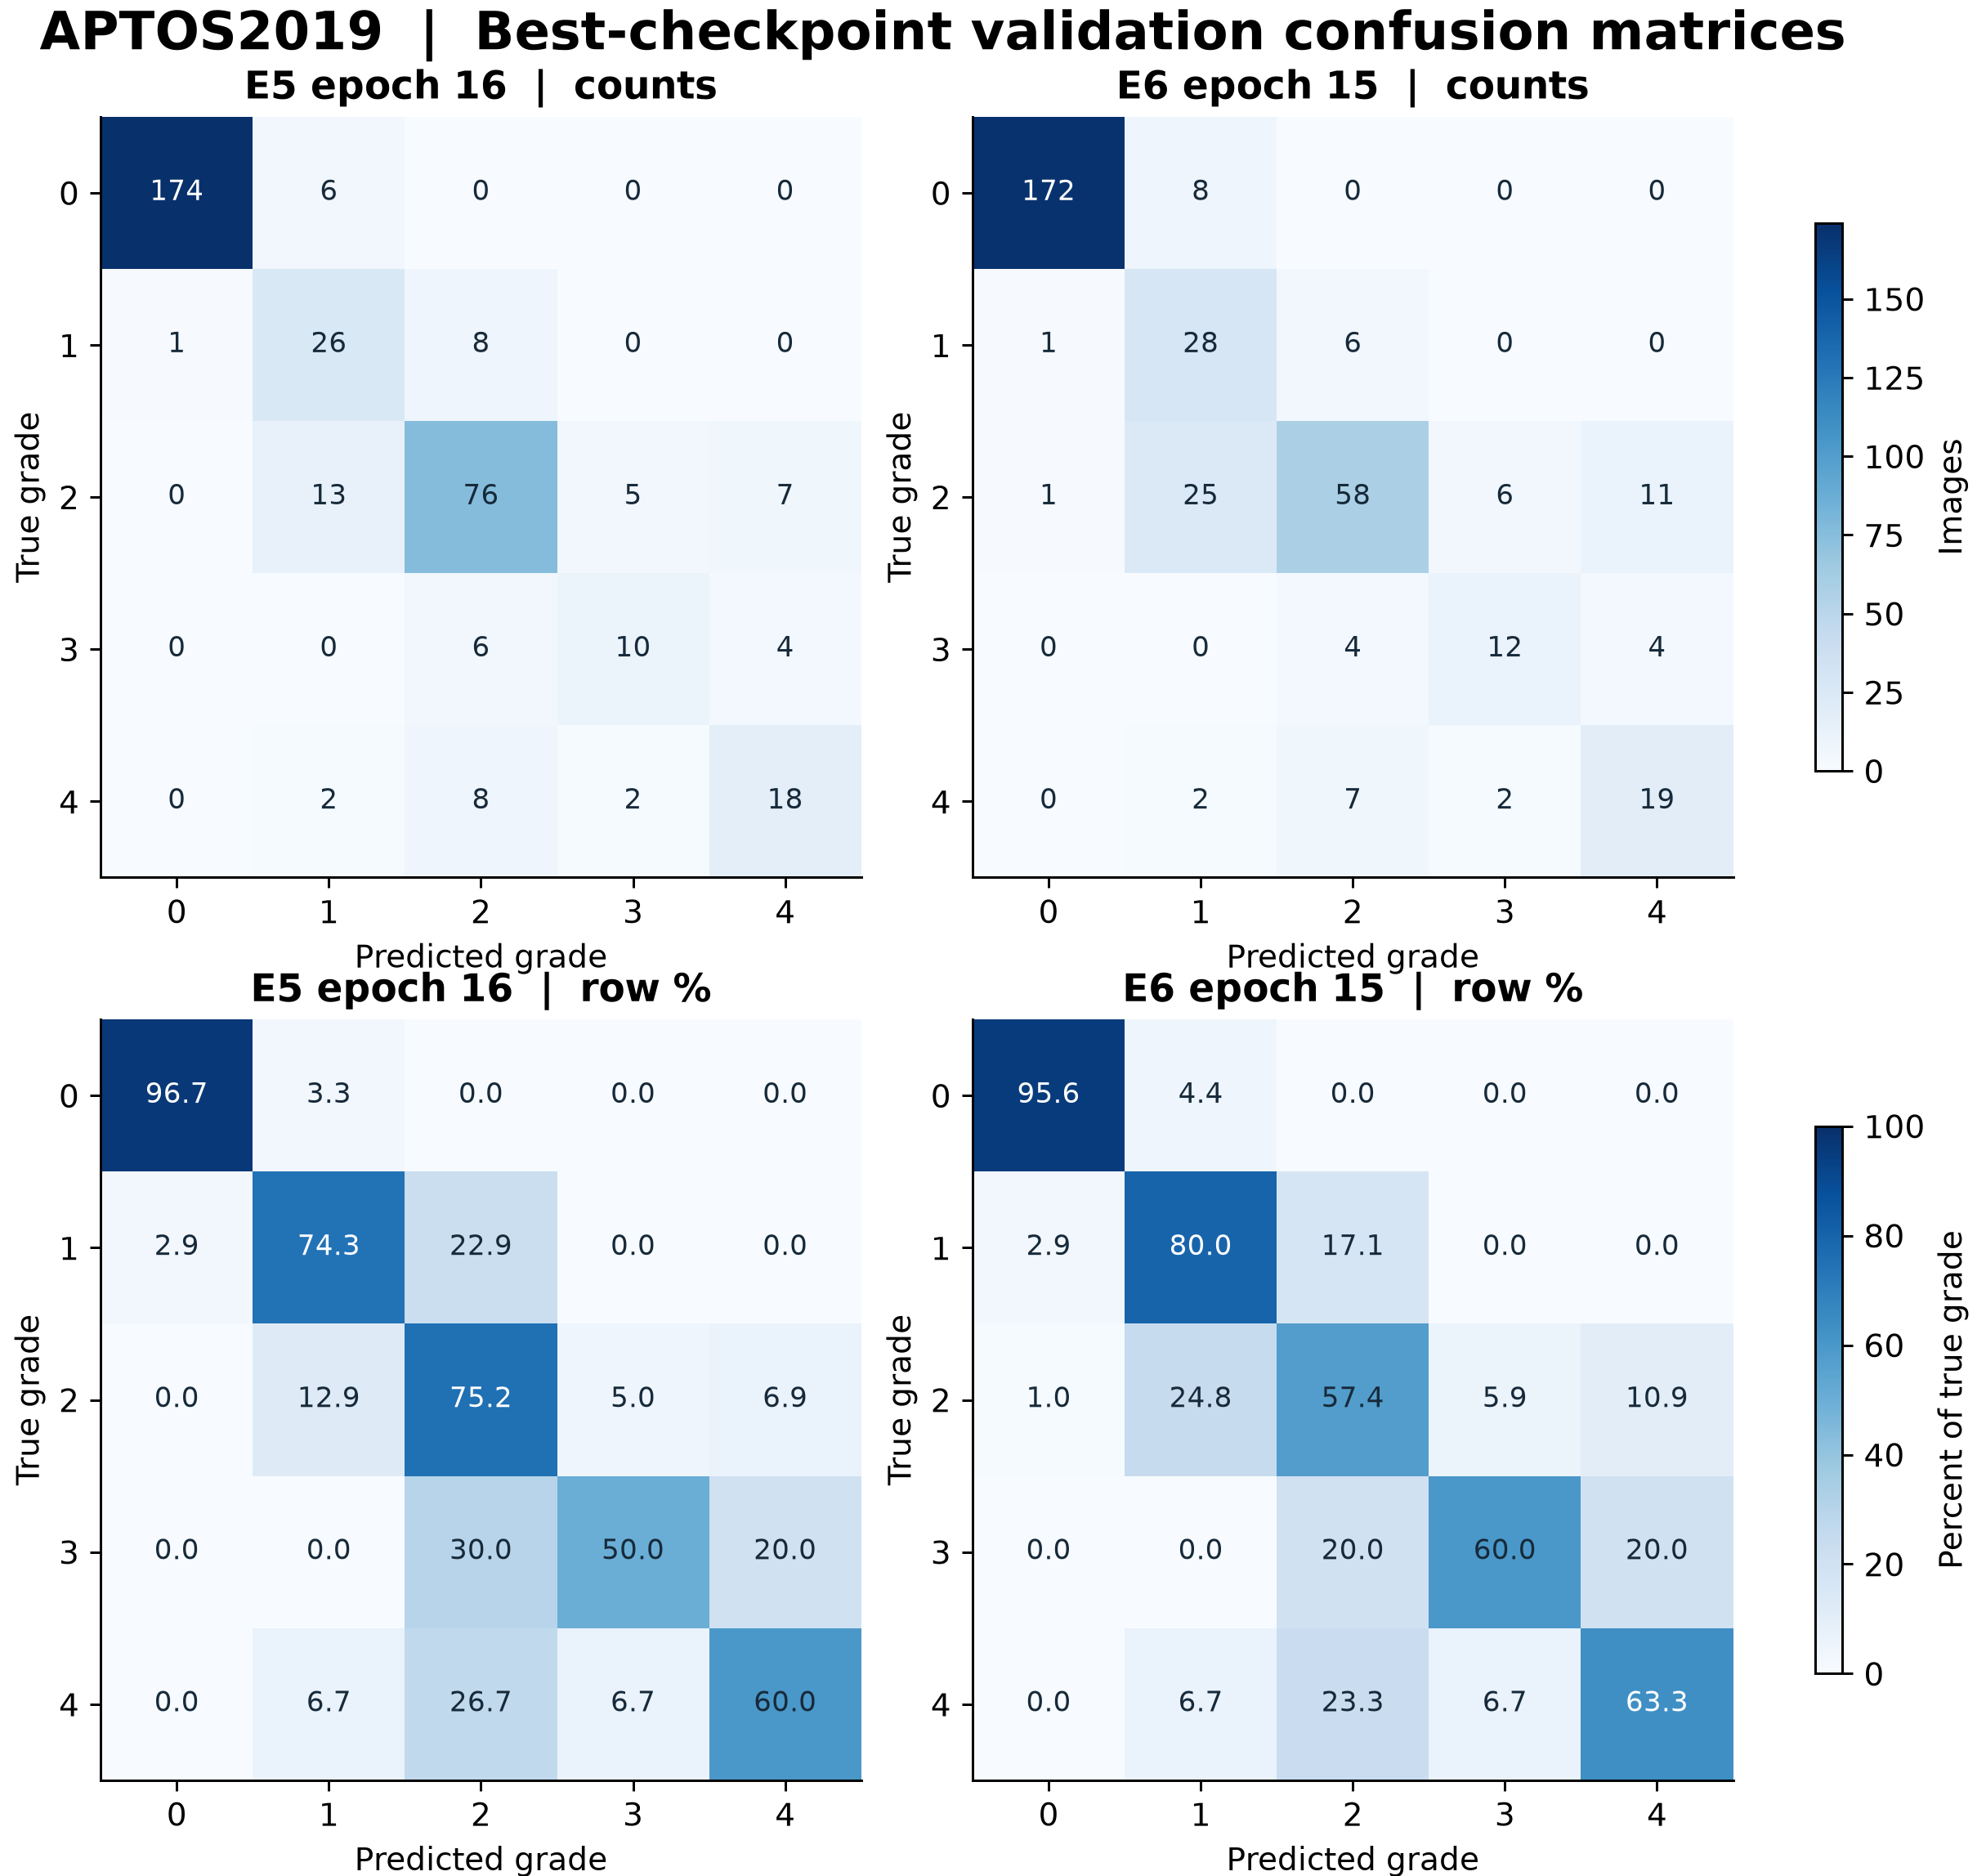

In [ ]:
from IPython.display import Image
display(Image(filename=str(ROOT / 'docs/figures/aptos2019_confusion.png')))

The saved score panel below places each method's selected epoch on the full recorded histories. Training and validation panels use their respective splits.

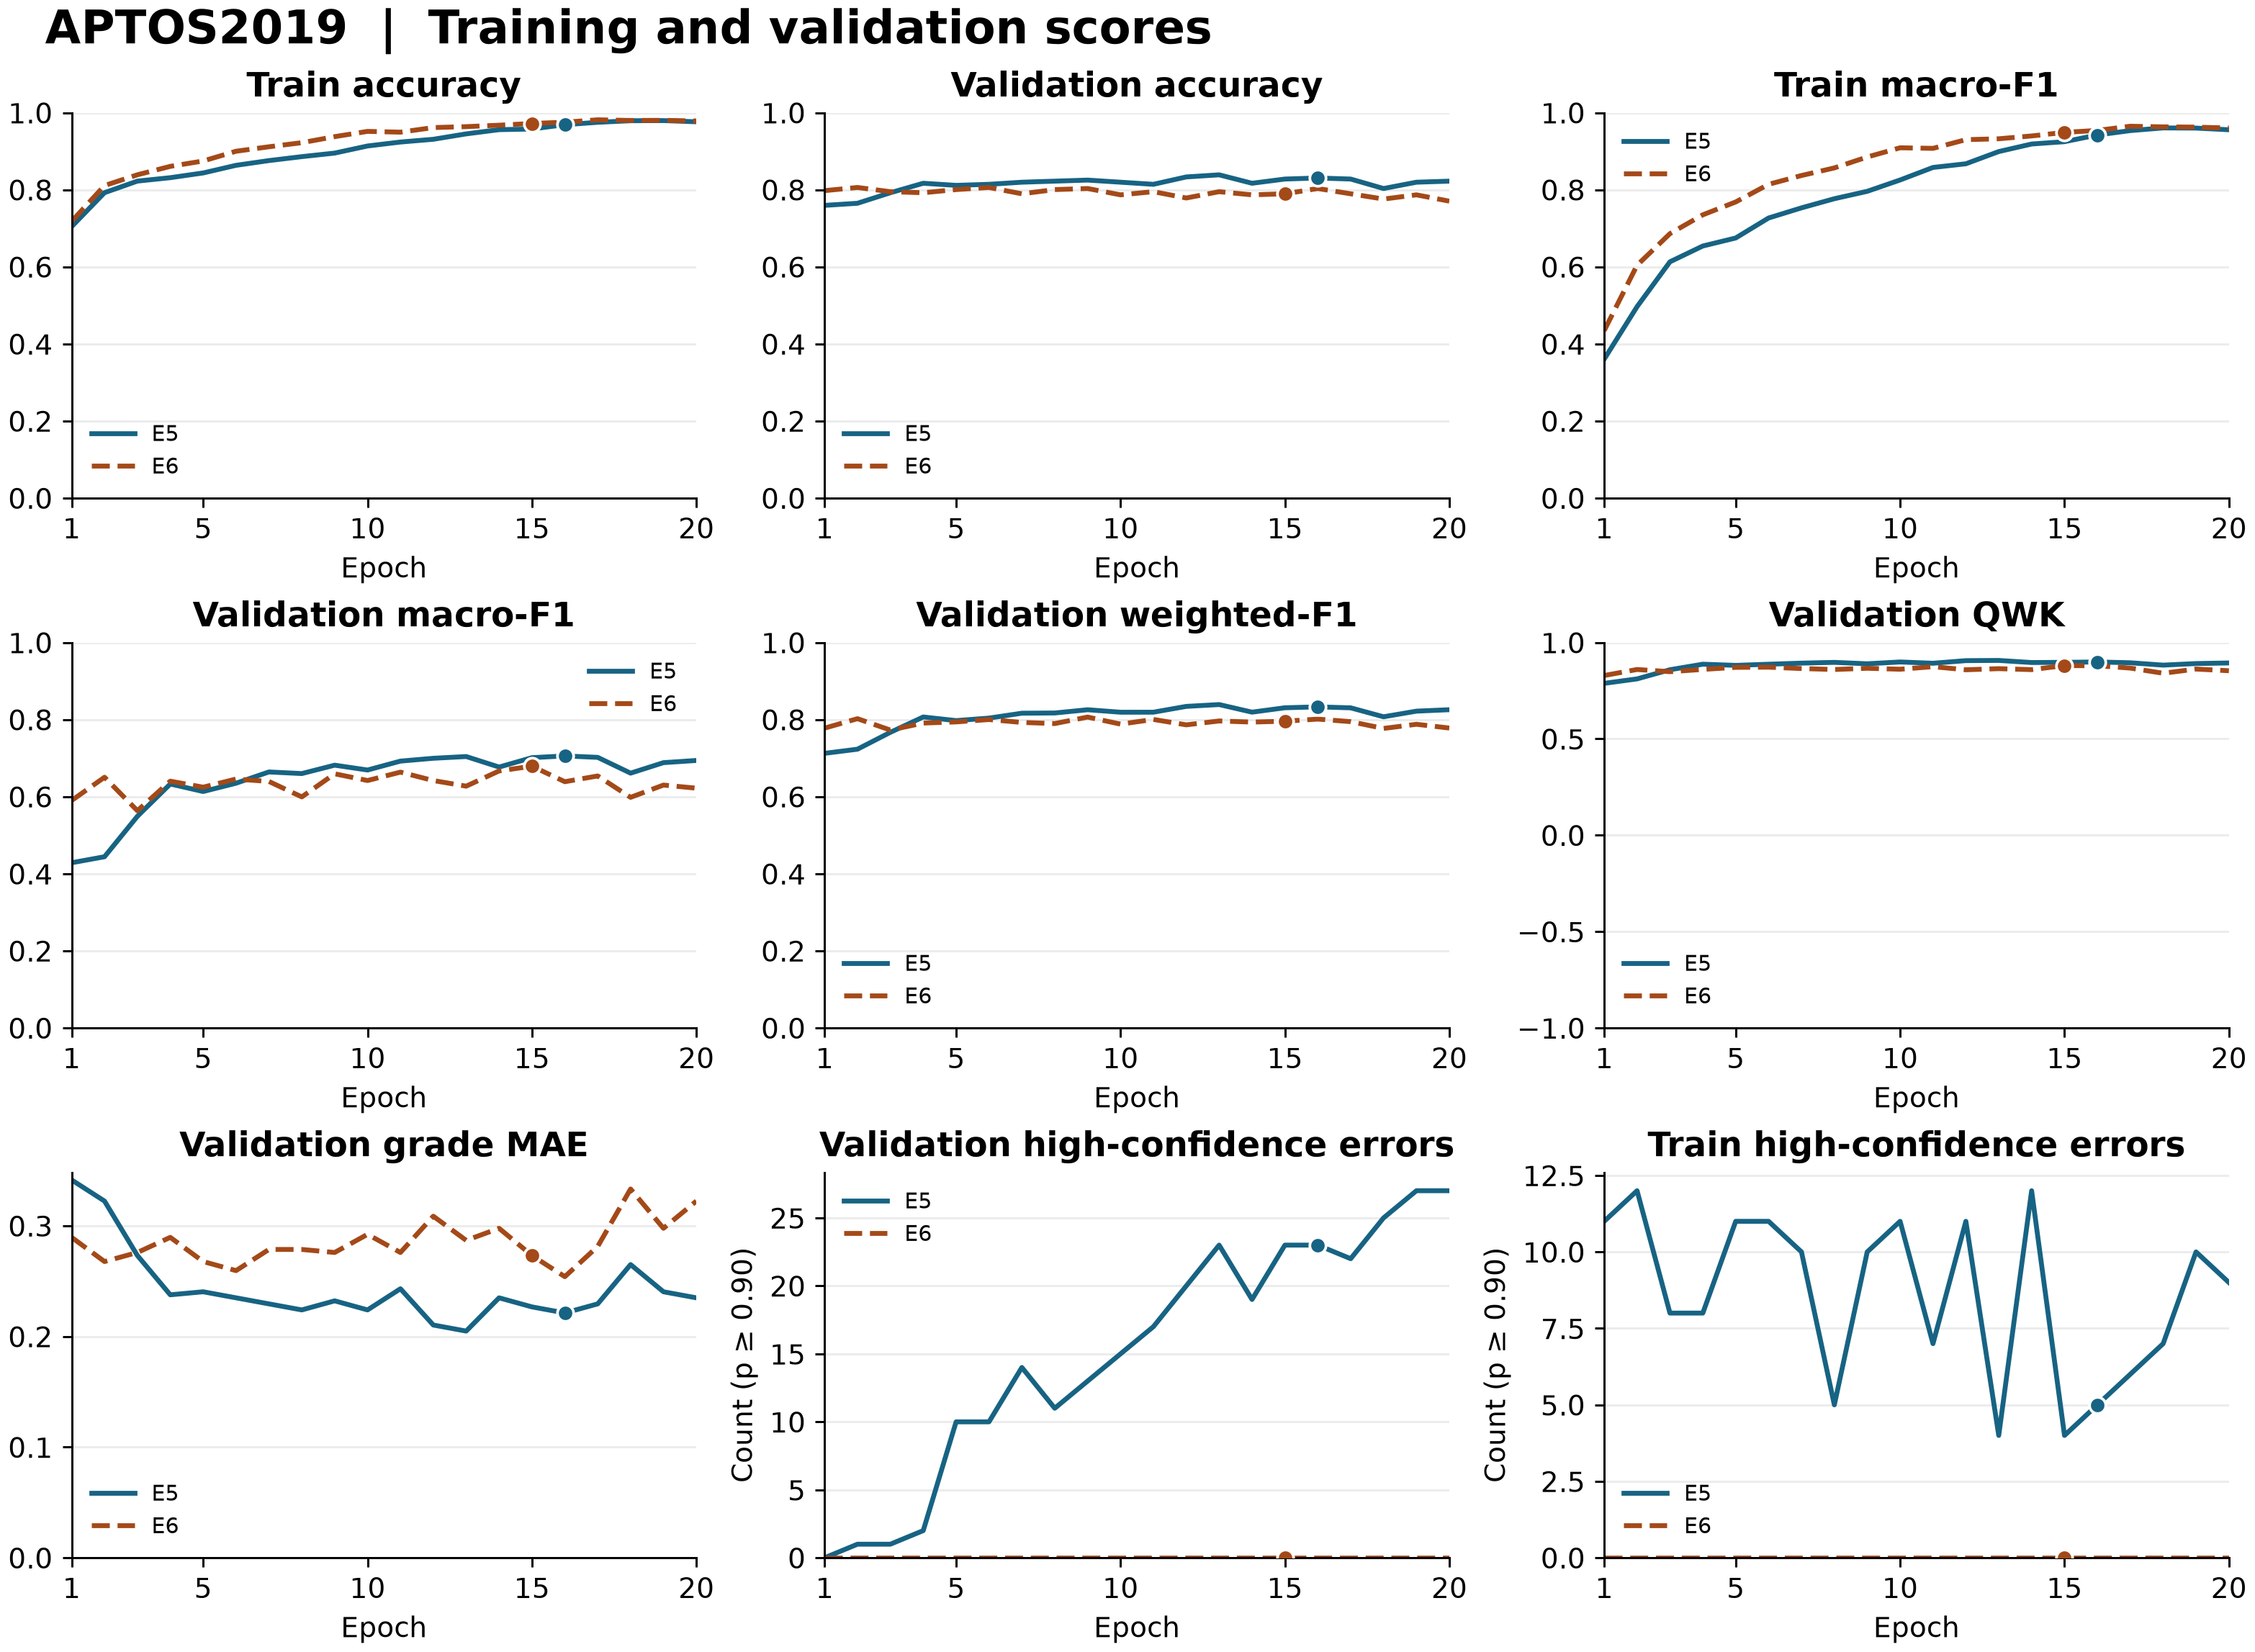

In [ ]:
from IPython.display import Image
display(Image(filename=str(ROOT / 'docs/figures/aptos2019_epoch_scores.png')))

## Interpretation and limits

On this dataset, E6 minus E5 is -0.026587 macro-F1, -0.040984 accuracy and -0.018857 QWK. See the comparison for grade 1 false positives, grade 3 recall and confidence-scale caveats.

Use the [E5–E6 comparison](../../docs/E5_E6_VALIDATION.md) for the dataset-specific trade-offs, including grade 1 false positives, grade 3 recall, and the confidence-scale audit. Validation selected the best epoch, so single-run differences are descriptive.

## Optional execution of the authentic workflow

Set the external `DR_ARTIFACT_ROOT`, `DR_CONVNEXT_SNAPSHOT` and for writing steps `DR_NOTEBOOK_RUN_DIR`. Use the protocol's reviewed cache roots, size budgets and paths when applicable. `DR_MANIFEST_SOURCE_ROOT` supports moved roots for E5–E7. Authorize the local snapshot explicitly via `DR_TRUST_LEGACY_BIN=1` where required. GPU actions also require `DR_GPU_ALLOCATION_CONFIRMED=1`. 

The [shared workflow bridge](../experiment_workflow.py) lists the exact environment keys and dispatches to the original CLI. Choose one step and enable its switch. Outputs must use a fresh external location. Report identity and cache validity remain enforced by the runner.

In [ ]:
from notebooks.experiment_workflow import run_step

ACTION = None
RUN_PREFLIGHT = False
RUN_CACHE = False
RUN_INPUT_VERIFICATION = False
RUN_GPU_SMOKE = False
RUN_BENCHMARK = False
RUN_TRAINING = False
RUN_CHECKPOINT_EXPORT = False
RUN_PRUNING = False
RUN_FINAL_TEST = False
if RUN_CHECKPOINT_EXPORT or RUN_PRUNING or RUN_FINAL_TEST:
    raise ValueError("Export, pruning and final-test inference are outside this workflow.")
run_step(ROOT, METHOD, DATASET, ACTION, CONFIG, {
    "preflight": RUN_PREFLIGHT, "estimate-cache": RUN_PREFLIGHT, "prepare-cache": RUN_CACHE,
    "verify-inputs": RUN_INPUT_VERIFICATION, "smoke": RUN_GPU_SMOKE,
    "benchmark": RUN_BENCHMARK, "train": RUN_TRAINING,
})